## Paso 1 Importar las librerías
Una **librería** es una caja de herramientas ya hecha. No tenemos que inventar todo desde cero.

- `pandas`: tablas (como Excel)
- `numpy`: cálculos
- `matplotlib` y `seaborn`: gráficas
- `scikit-learn`: machine learning
- `statsmodels`: estadística (p-valores e intervalos de confianza)
- `joblib`: guardar el modelo

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import joblib

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

sns.set_theme(style="whitegrid")
print("Librerías listas")

Librerías listas


In [2]:
df = pd.read_csv("dataset_precio_gasolina__1_.csv", parse_dates=["Fecha"])

print("Filas y columnas:", df.shape)
df.head()

Filas y columnas: (72, 10)


,Fecha,Precio_Gasolina_USD_Galon,Precio_Petroleo_USD_Barril,Tipo_Cambio_USD_COP,Demanda_miles_barriles_dia,Produccion_OPEP_millones_dia,Inflacion_Porcentaje,PIB_Porcentaje,Eventos_Geopoliticos,Impuestos_Combustibles_Porcentaje
0,2018-01-01,8.17,73.94,3683.88,9673.0,27.45,3.84,3.54,1,18
1,2018-02-01,8.51,62.51,4404.09,9819.0,28.53,2.75,5.57,0,22
2,2018-03-01,8.17,76.66,2521.11,9254.0,28.03,3.25,2.28,0,22
3,2018-04-01,9.09,92.41,4069.86,9230.0,29.16,2.91,3.30,0,22
4,2018-05-01,8.10,60.79,3739.17,9746.0,33.63,2.79,3.88,0,18


In [3]:
print("=== Información general ===")
df.info()

print("\n=== Valores faltantes por columna ===")
print(df.isnull().sum())

=== Información general ===
<class 'pandas.DataFrame'>
RangeIndex: 72 entries, 0 to 71
Data columns (total 10 columns):
 #   Column                             Non-Null Count  Dtype         
---  ------                             --------------  -----         
 0   Fecha                              72 non-null     datetime64[us]
 1   Precio_Gasolina_USD_Galon          72 non-null     float64       
 2   Precio_Petroleo_USD_Barril         72 non-null     float64       
 3   Tipo_Cambio_USD_COP                72 non-null     float64       
 4   Demanda_miles_barriles_dia         72 non-null     float64       
 5   Produccion_OPEP_millones_dia       72 non-null     float64       
 6   Inflacion_Porcentaje               72 non-null     float64       
 7   PIB_Porcentaje                     72 non-null     float64       
 8   Eventos_Geopoliticos               72 non-null     int64         
 9   Impuestos_Combustibles_Porcentaje  72 non-null     int64         
dtypes: datetime64[us](1), f

In [4]:

df.describe().T.round(2)

,count,mean,min,25%,50%,75%,max,std
Fecha,72,2020-12-15 15:20:00,2018-01-01 00:00:00,2019-06-23 12:00:00,2020-12-16 12:00:00,2022-06-08 12:00:00,2023-12-01 00:00:00,NaN
Precio_Gasolina_USD_Galon,72.0,8.104444,6.56,7.4875,8.08,8.73,10.5,0.790899
Precio_Petroleo_USD_Barril,72.0,63.117778,29.73,53.2475,62.085,74.1475,98.34,16.38322
Tipo_Cambio_USD_COP,72.0,3674.238611,2521.11,3429.8975,3686.225,3889.645,4808.46,444.171734
Demanda_miles_barriles_dia,72.0,9652.069444,9176.0,9407.5,9682.5,9788.0,10679.0,270.140304
Produccion_OPEP_millones_dia,72.0,28.897778,25.0,27.5175,28.825,30.33,33.63,2.134165
Inflacion_Porcentaje,72.0,3.563333,1.76,2.8275,3.51,4.25,6.01,0.883983
PIB_Porcentaje,72.0,2.779167,-1.75,1.225,2.735,4.405,6.88,2.120914
Eventos_Geopoliticos,72.0,0.138889,0.0,0.0,0.0,0.0,1.0,0.348257
Impuestos_Combustibles_Porcentaje,72.0,22.180556,18.0,21.0,22.0,25.0,30.0,3.229819


**3.3 Correlación**: mide de -1 a 1 qué tan relacionada está cada variable con el precio.
- Cerca de **1**: cuando sube una, sube la otra.
- Cerca de **-1**: cuando sube una, baja la otra.
- Cerca de **0**: casi no se relacionan.

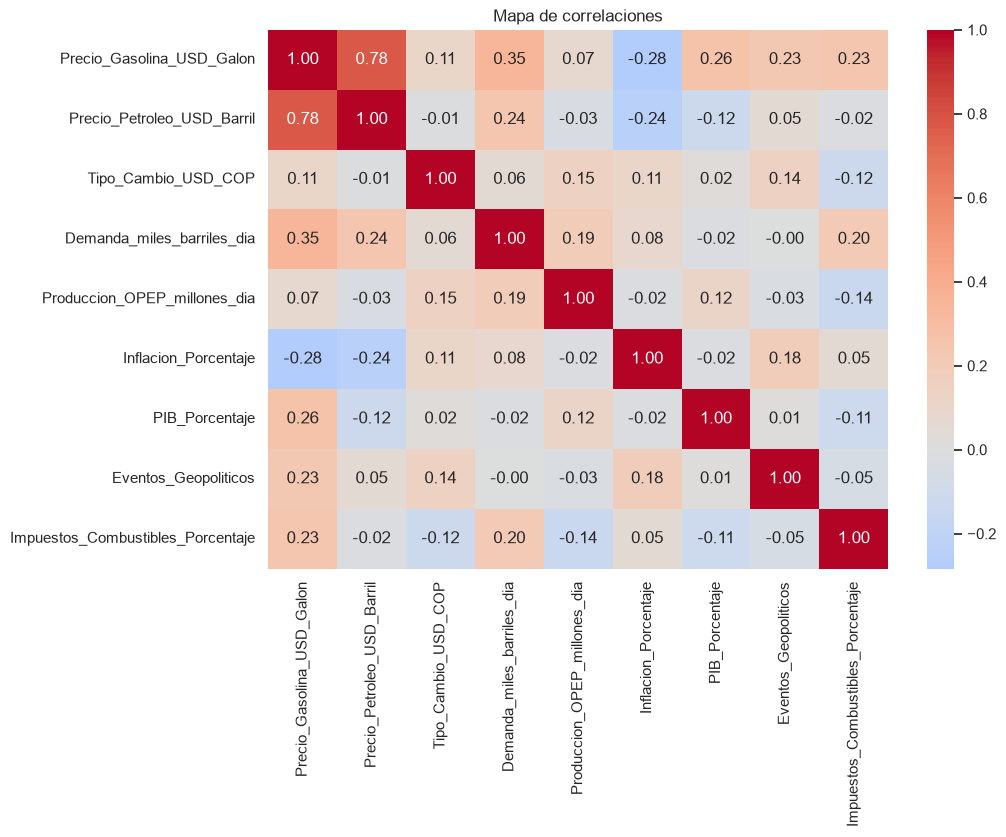

Correlación de cada variable con el precio de la gasolina:
Precio_Petroleo_USD_Barril           0.777
Demanda_miles_barriles_dia           0.350
PIB_Porcentaje                       0.263
Impuestos_Combustibles_Porcentaje    0.234
Eventos_Geopoliticos                 0.227
Tipo_Cambio_USD_COP                  0.109
Produccion_OPEP_millones_dia         0.073
Inflacion_Porcentaje                -0.284
Name: Precio_Gasolina_USD_Galon, dtype: float64


In [5]:
TARGET = "Precio_Gasolina_USD_Galon"

corr = df.drop(columns="Fecha").corr()

plt.figure(figsize=(10, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Mapa de correlaciones")
plt.show()

print("Correlación de cada variable con el precio de la gasolina:")
print(corr[TARGET].drop(TARGET).sort_values(ascending=False).round(3))

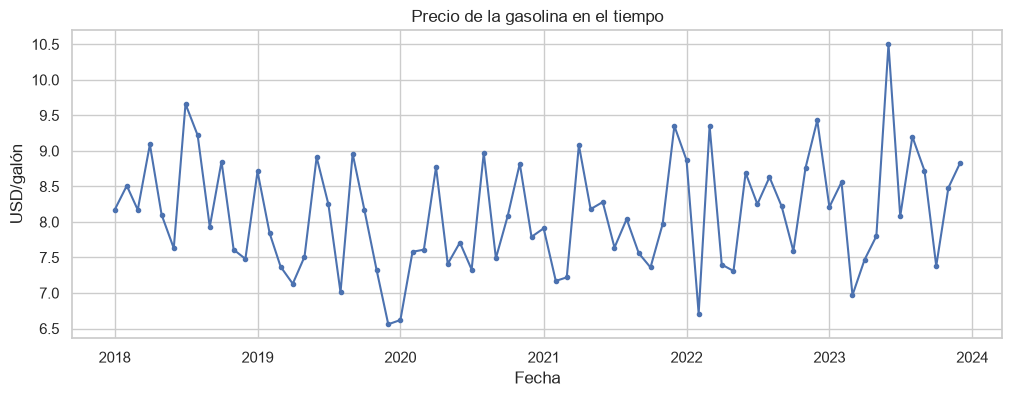

In [6]:
plt.figure(figsize=(12, 4))
plt.plot(df["Fecha"], df[TARGET], marker="o", markersize=3)
plt.title("Precio de la gasolina en el tiempo")
plt.xlabel("Fecha"); plt.ylabel("USD/galón")
plt.show()

## Paso 4 Limpieza de datos
### 4.1 Valores faltantes
Un valor faltante es una celda vacía. Si hubiera, la rellenamos con la **mediana** (el valor del medio). En este dataset hay 0, pero dejamos el código por si el profesor usa otro archivo.

In [7]:
columnas_numericas = [c for c in df.columns if c != "Fecha"]

for col in columnas_numericas:
    if df[col].isnull().sum() > 0:
        df[col] = df[col].fillna(df[col].median())

print("Faltantes después de limpiar:", df.isnull().sum().sum())

Faltantes después de limpiar: 0


### 4.2 Valores atípicos (outliers)
Un **atípico** es un dato muy raro, muy lejos de los demás (por ejemplo, un dólar a 10.000 pesos por error).

Usamos la **regla del IQR**:
- Q1 = el 25% de los datos está por debajo; Q3 = el 75%.
- IQR = Q3 − Q1.
- Es atípico lo que esté **por debajo de Q1 − 1.5·IQR** o **por encima de Q3 + 1.5·IQR**.

En vez de borrar filas (solo tenemos 72), **los recortamos** a ese límite. Esto se llama *winsorización*.
Las variables 0/1 (`Eventos_Geopoliticos`) y `Impuestos_Combustibles_Porcentaje` (solo toma pocos valores fijos) **no** se recortan.

In [8]:
vars_continuas = [
    "Precio_Petroleo_USD_Barril", "Tipo_Cambio_USD_COP", "Demanda_miles_barriles_dia",
    "Produccion_OPEP_millones_dia", "Inflacion_Porcentaje", "PIB_Porcentaje",
]

limites = {}
for col in vars_continuas:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    inf, sup = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    limites[col] = (inf, sup)
    n_atip = ((df[col] < inf) | (df[col] > sup)).sum()
    print(f"{col:35s} atípicos: {n_atip}   límites: [{inf:.2f}, {sup:.2f}]")

Precio_Petroleo_USD_Barril          atípicos: 0   límites: [21.90, 105.50]
Tipo_Cambio_USD_COP                 atípicos: 3   límites: [2740.28, 4579.27]
Demanda_miles_barriles_dia          atípicos: 2   límites: [8836.75, 10358.75]
Produccion_OPEP_millones_dia        atípicos: 0   límites: [23.30, 34.55]
Inflacion_Porcentaje                atípicos: 0   límites: [0.69, 6.38]
PIB_Porcentaje                      atípicos: 0   límites: [-3.55, 9.18]


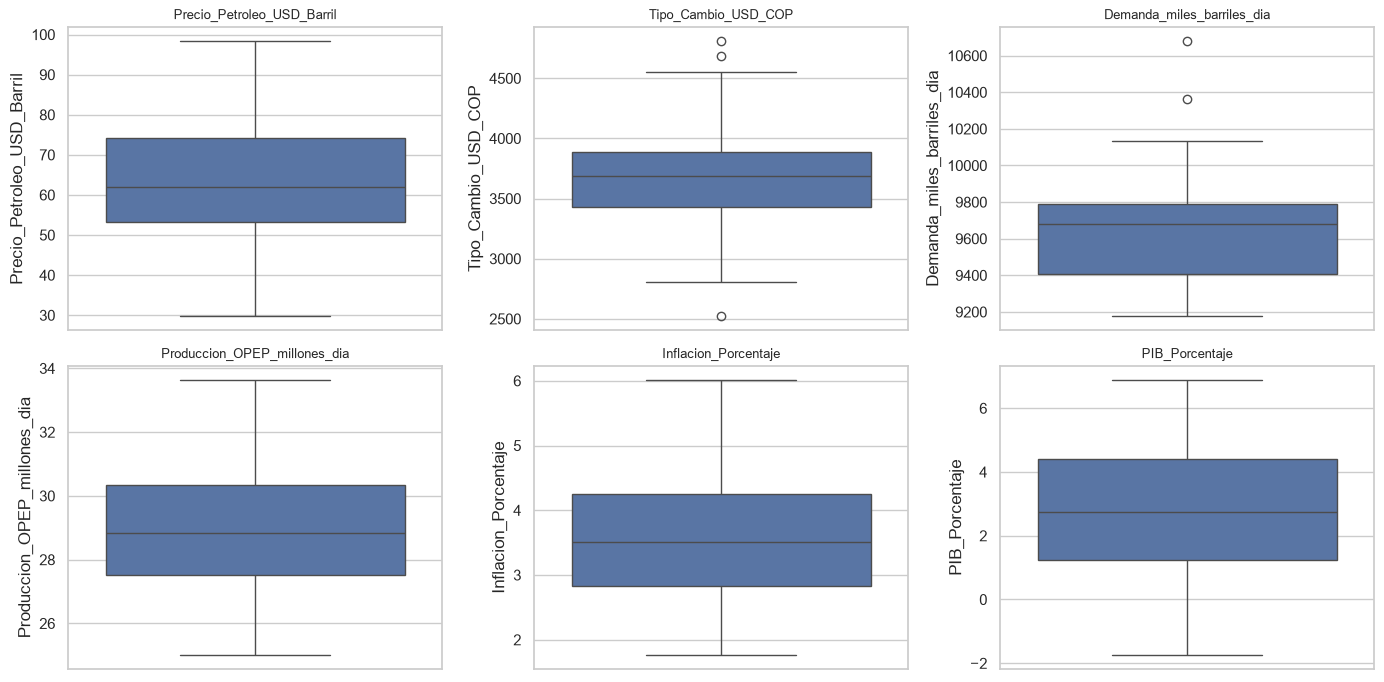

In [9]:
#Grafica de variables
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, col in zip(axes.ravel(), vars_continuas):
    sns.boxplot(y=df[col], ax=ax)
    ax.set_title(col, fontsize=9)
plt.tight_layout(); plt.show()

In [10]:
for col, (inf, sup) in limites.items():
    df[col] = df[col].clip(lower=inf, upper=sup)

print("Atípicos tratados")

Atípicos tratados


In [11]:
RANDOM_STATE = 99

X = df.drop(columns=["Fecha", TARGET]) 
y = df[TARGET]                            

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=RANDOM_STATE
)

print("Entrenamiento:", X_train.shape[0], "filas (70%)")
print("Prueba       :", X_test.shape[0], "filas (30%)")

Entrenamiento: 50 filas (70%)
Prueba       : 22 filas (30%)


## Paso 6️ Selección de características (análisis estadístico)
No todas las variables ayudan. Algunas solo meten ruido.

Usamos el **p-valor**: un número entre 0 y 1 que responde *"¿esta variable de verdad influye, o fue casualidad?"*
- **p < 0.05** → sí influye (la dejamos)
- **p ≥ 0.05** → probablemente no aporta (la quitamos)

Método: **eliminación hacia atrás**. Ajustamos el modelo, quitamos la variable con p-valor más alto (si es ≥ 0.05) y repetimos hasta que todas queden con p < 0.05.


In [12]:
variables = list(X_train.columns)

while True:
    modelo_tmp = sm.OLS(y_train, sm.add_constant(X_train[variables])).fit()
    pvalores = modelo_tmp.pvalues.drop("const")
    peor = pvalores.idxmax()
    if pvalores[peor] >= 0.05:
        print(f"Quitamos {peor} (p-valor = {pvalores[peor]:.3f})")
        variables.remove(peor)
    else:
        break

print("\n Variables seleccionadas:")
for v in variables:
    print("  -", v)

Quitamos Demanda_miles_barriles_dia (p-valor = 0.347)
Quitamos Produccion_OPEP_millones_dia (p-valor = 0.071)

 Variables seleccionadas:
  - Precio_Petroleo_USD_Barril
  - Tipo_Cambio_USD_COP
  - Inflacion_Porcentaje
  - PIB_Porcentaje
  - Eventos_Geopoliticos
  - Impuestos_Combustibles_Porcentaje


In [13]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

Xv = sm.add_constant(X_train[variables])
vif = pd.DataFrame({
    "Variable": Xv.columns,
    "VIF": [variance_inflation_factor(Xv.values, i) for i in range(Xv.shape[1])]
}).query("Variable != 'const'")
vif.round(2)

,Variable,VIF
1,Precio_Petroleo_USD_Barril,1.07
2,Tipo_Cambio_USD_COP,1.06
3,Inflacion_Porcentaje,1.15
4,PIB_Porcentaje,1.01
5,Eventos_Geopoliticos,1.09
6,Impuestos_Combustibles_Porcentaje,1.06


## Paso 7️ Normalización (estandarizar)
Las variables tienen escalas muy distintas: el dólar vale ~3.600 y la inflación ~3.5. Para que ninguna "grite más fuerte" por tener números grandes, las pasamos a la **misma escala**:

**valor_nuevo = (valor − promedio) / desviación**

Así todas quedan con promedio 0 y desviación 1. Se llama `StandardScaler`.
Se calcula el promedio y la desviación **solo con entrenamiento** (`fit`) y luego se aplica igual a prueba (`transform`).

In [14]:
scaler = StandardScaler()
scaler.fit(X_train[variables])

X_train_s = pd.DataFrame(scaler.transform(X_train[variables]), columns=variables, index=X_train.index)
X_test_s  = pd.DataFrame(scaler.transform(X_test[variables]),  columns=variables, index=X_test.index)

X_train_s.describe().loc[["mean", "std"]].round(2)

,Precio_Petroleo_USD_Barril,Tipo_Cambio_USD_COP,Inflacion_Porcentaje,PIB_Porcentaje,Eventos_Geopoliticos,Impuestos_Combustibles_Porcentaje
mean,-0.00,-0.00,0.00,0.00,-0.00,0.00
std,1.01,1.01,1.01,1.01,1.01,1.01


## Paso 8️ Entrenar el modelo de Regresión Lineal
La regresión lineal busca esta fórmula:

**precio = b0 + b1·variable1 + b2·variable2 + ...**

Cada **b** dice cuánto cambia el precio cuando esa variable sube. Usamos `statsmodels` porque además nos da el **intervalo de confianza**.

In [15]:
X_train_c = sm.add_constant(X_train_s)          
modelo = sm.OLS(y_train, X_train_c).fit()       

print(modelo.summary())

                                OLS Regression Results                               
Dep. Variable:     Precio_Gasolina_USD_Galon   R-squared:                       0.874
Model:                                   OLS   Adj. R-squared:                  0.856
Method:                        Least Squares   F-statistic:                     49.51
Date:                       Tue, 13 Oct 2026   Prob (F-statistic):           1.00e-17
Time:                               14:05:01   Log-Likelihood:                -5.3903
No. Observations:                         50   AIC:                             24.78
Df Residuals:                             43   BIC:                             38.16
Df Model:                                  6                                         
Covariance Type:                   nonrobust                                         
                                        coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------

## Paso 9️ Evaluar el modelo (con el 30% de prueba)
| Métrica | ¿Qué significa? | ¿Qué es bueno? |
|---|---|---|
| **R²** | % de lo que el modelo logra explicar | Entre **0.90 y 1** (la meta) |
| **MSE** | Error promedio **al cuadrado** | Más cerca de 0 |
| **RMSE** | Raíz del MSE (en USD/galón) | Más cerca de 0 |
| **MAE** | Error promedio en USD/galón | Más cerca de 0 |

In [16]:
X_test_c = sm.add_constant(X_test_s, has_constant="add")
pred_test = modelo.predict(X_test_c)
pred_train = modelo.predict(X_train_c)

def metricas(y_real, y_pred, nombre):
    mse = mean_squared_error(y_real, y_pred)
    return {"Conjunto": nombre,
            "R²": r2_score(y_real, y_pred),
            "RMSE": np.sqrt(mse),
            "MAE": mean_absolute_error(y_real, y_pred)}

resultados = pd.DataFrame([metricas(y_train, pred_train, "Entrenamiento (70%)"),
                           metricas(y_test,  pred_test,  "Prueba (30%)")]).set_index("Conjunto")
display(resultados.round(4))

r2_prueba = resultados.loc["Prueba (30%)", "R²"]
if 0.90 < r2_prueba < 1:
    print(f" CUMPLE el requisito: R² = {r2_prueba:.4f} (entre 0.90 y 1)")
else:
    print(f" NO cumple: R² = {r2_prueba:.4f}")

,R²,RMSE,MAE
Conjunto,,,
Entrenamiento (70%),0.8736,0.2695,0.2126
Prueba (30%),0.9151,0.2458,0.1967


 CUMPLE el requisito: R² = 0.9151 (entre 0.90 y 1)


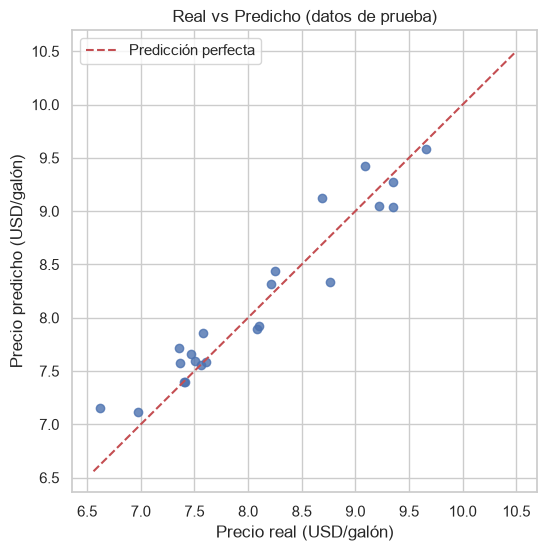

In [17]:
# Gráfica de predicciones
plt.figure(figsize=(6, 6))
plt.scatter(y_test, pred_test, alpha=0.8)
mn, mx = y.min(), y.max()
plt.plot([mn, mx], [mn, mx], "r--", label="Predicción perfecta")
plt.xlabel("Precio real (USD/galón)"); plt.ylabel("Precio predicho (USD/galón)")
plt.title("Real vs Predicho (datos de prueba)")
plt.legend(); plt.show()

R² promedio en 100 sorteos : 0.853
R² mínimo / máximo         : 0.663 / 0.943
% de sorteos con R² > 0.90 : 11%


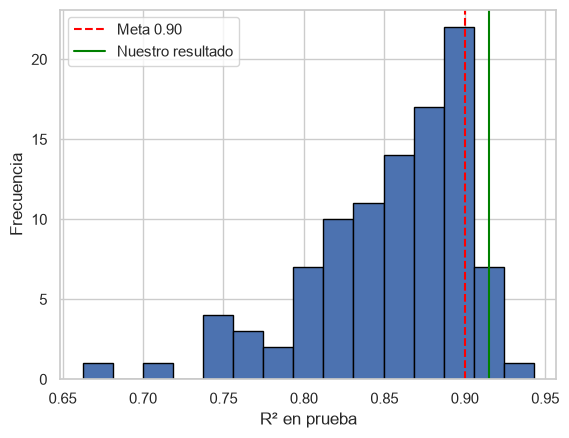

In [18]:
r2_lista = []
for semilla in range(100):
    Xa, Xb, ya, yb = train_test_split(X, y, test_size=0.30, random_state=semilla)
    sc = StandardScaler().fit(Xa[variables])
    m = sm.OLS(ya, sm.add_constant(sc.transform(Xa[variables]))).fit()
    pb = m.predict(sm.add_constant(sc.transform(Xb[variables]), has_constant="add"))
    r2_lista.append(r2_score(yb, pb))

r2_lista = np.array(r2_lista)
print(f"R² promedio en 100 sorteos : {r2_lista.mean():.3f}")
print(f"R² mínimo / máximo         : {r2_lista.min():.3f} / {r2_lista.max():.3f}")
print(f"% de sorteos con R² > 0.90 : {(r2_lista > 0.90).mean()*100:.0f}%")

plt.hist(r2_lista, bins=15, edgecolor="black")
plt.axvline(0.90, color="red", linestyle="--", label="Meta 0.90")
plt.axvline(r2_prueba, color="green", label="Nuestro resultado")
plt.xlabel("R² en prueba"); plt.ylabel("Frecuencia"); plt.legend(); plt.show()

## Paso 10 Predicción con intervalo de confianza del 95%
Un **intervalo de predicción al 95%** dice: *"el precio real estará entre A y B con 95% de probabilidad"*. Es más honesto que dar un solo número.

Primero lo hacemos con los datos de prueba, y luego con un **ejemplo nuevo** escrito a mano.

In [19]:
pred_ic = modelo.get_prediction(X_test_c).summary_frame(alpha=0.05)

tabla = pd.DataFrame({
    "Precio real": y_test.values,
    "Predicción": pred_ic["mean"].values,
    "Mínimo (95%)": pred_ic["obs_ci_lower"].values,
    "Máximo (95%)": pred_ic["obs_ci_upper"].values,
}, index=df.loc[y_test.index, "Fecha"].dt.strftime("%Y-%m")).sort_index()

display(tabla.round(2).head(10))

dentro = ((tabla["Precio real"] >= tabla["Mínimo (95%)"]) & (tabla["Precio real"] <= tabla["Máximo (95%)"])).mean()
print(f"Porcentaje de valores reales dentro del intervalo: {dentro*100:.0f}%")

,Precio real,Predicción,Mínimo (95%),Máximo (95%)
Fecha,,,,
2018-04,9.09,9.43,8.81,10.05
2018-05,8.10,7.92,7.31,8.53
2018-07,9.66,9.59,8.91,10.26
2018-08,9.22,9.05,8.34,9.76
2018-11,7.61,7.59,6.95,8.23
2019-03,7.37,7.58,6.93,8.23
2019-05,7.51,7.60,6.99,8.20
2020-01,6.62,7.15,6.53,7.77
2020-02,7.58,7.86,7.24,8.48


Porcentaje de valores reales dentro del intervalo: 100%


In [20]:
nuevo = {
    "Precio_Petroleo_USD_Barril": 75.0,
    "Tipo_Cambio_USD_COP": 3900.0,
    "Demanda_miles_barriles_dia": 9700.0,
    "Produccion_OPEP_millones_dia": 29.0,
    "Inflacion_Porcentaje": 3.5,
    "PIB_Porcentaje": 3.0,
    "Eventos_Geopoliticos": 0,
    "Impuestos_Combustibles_Porcentaje": 22,
}

fila = pd.DataFrame([nuevo])[variables]                 
fila_s = pd.DataFrame(scaler.transform(fila), columns=variables)
fila_c = sm.add_constant(fila_s, has_constant="add")
res = modelo.get_prediction(fila_c).summary_frame(alpha=0.05)

print(f" Precio predicho : {res['mean'].iloc[0]:.2f} USD/galón")
print(f" Intervalo 95%   : [{res['obs_ci_lower'].iloc[0]:.2f} , {res['obs_ci_upper'].iloc[0]:.2f}] USD/galón")

 Precio predicho : 8.61 USD/galón
 Intervalo 95%   : [8.02 , 9.21] USD/galón


## Paso 11 Guardar el modelo para el aplicativo
Guardamos el modelo, el normalizador y la lista de variables en un archivo. Así el aplicativo (Streamlit) los carga **sin volver a entrenar**.

In [21]:
paquete = {
    "modelo": modelo,
    "scaler": scaler,
    "variables": variables,
    "rangos": {c: (float(df[c].min()), float(df[c].max())) for c in X.columns},
    "medianas": {c: float(df[c].median()) for c in X.columns},
    "metricas": resultados.loc["Prueba (30%)"].to_dict(),
    "n_train": int(len(X_train)),
    "n_test": int(len(X_test)),
}
joblib.dump(paquete, "modelo_gasolina.pkl")
print("Guardado: modelo_gasolina.pkl")

Guardado: modelo_gasolina.pkl


## Conclusiones 
- Se limpiaron los datos (sin faltantes; atípicos recortados con IQR).
- Se dividió 70/30 y se normalizó con `StandardScaler` (ajustado solo con entrenamiento).
- Se seleccionaron variables con p-valores (eliminación hacia atrás).
- El modelo de **Regresión Lineal** se evaluó con R²,RMSE y MAE.
- Se generó una predicción con **intervalo de confianza del 95%**.
- El modelo quedó guardado para el aplicativo web (`app.py`).